In [1]:
# 基础库
import numpy as np
import xarray as xr
import os
import sys
import gc  
import pickle
import pandas as pd

# 统计分析库
import statsmodels.api as sm
from scipy.stats import norm, ttest_1samp
import pymannkendall as mk
from scipy.stats import pearsonr
from scipy.stats import linregress

# 地理空间处理库
from shapely.geometry import Point
import geopandas as gpd

# 并行处理库
from multiprocessing import Pool, cpu_count

# 可视化库
from matplotlib import gridspec, pyplot as plt
from matplotlib.ticker import MultipleLocator
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import LinearSegmentedColormap
import warnings
warnings.filterwarnings("ignore")

# 自定义模块
sys.path.append('/public/home/zhujw/work/guoly/code/Self-package/ccg_filter')
import ccg_filter

def cal_area_grid(lat, lon, radius=6371000):
    lat_rad = np.radians(lat)
    lat_diff = np.diff(lat_rad) / 2  # 使用中间差值
    
    area = np.zeros((len(lat), len(lon)))
    
    lat_area_factors = radius ** 2 * np.abs(
        np.sin(lat_rad[:-1] + lat_diff) - np.sin(lat_rad[:-1] - lat_diff)
    )

    lon_diff = np.abs(np.radians(lon[1] - lon[0]))

    area[:-1, :] = lat_area_factors[:, np.newaxis] * lon_diff
    area[-1, :] = area[-2, :] 
    area[:, -1] = area[:, -2] 
    
    return area

def cal_mean_base_area(area, lon, lat, data, lat_dis=None, lon_dis=None, mask_type=None):
    """
    计算基于面积加权的区域平均值，支持按纬度带、经度带划分或全区域计算。

    参数:
    - area: 全球格点面积 (2D 数组)
    - lon: 经度数组 (1D)
    - lat: 纬度数组 (1D)
    - data: 待计算的三维数据 (时间, 纬度, 经度)
    - lat_dis: 纬度带划分 (1D 数组, 可选)
    - lon_dis: 经度带划分 (1D 数组, 可选)
    - mask_type: 掩码类型 ('land' 或 'ocean', 可选)

    返回:
    - data_sum: 按纬度带、经度带或全区域加权平均的结果
    """
    # 创建掩码网格
    if mask_type is not None:
        shapefile_path = '/public/home/zhujw/work/guoly/data/SHP/ne_110m_land/ne_110m_land.shp'
        gdf = gpd.read_file(shapefile_path)
        lon_grid, lat_grid = np.meshgrid(lon, lat)
        points = [Point(x, y) for x, y in zip(lon_grid.ravel(), lat_grid.ravel())]
        grid_gdf = gpd.GeoDataFrame(geometry=points, crs="EPSG:4326")
        mask = grid_gdf.geometry.apply(lambda x: any(gdf.contains(x)))
        mask_2d = mask.values.reshape(lat_grid.shape)

    # 根据掩码类型选择区域
    if mask_type == 'land':
        area_mask = np.where(mask_2d, area, np.nan)
    elif mask_type == 'ocean':
        area_mask = np.where(~mask_2d, area, np.nan)
    else:
        area_mask = area

    # 加权数据
    data_mask = data * np.tile(area_mask, (data.shape[0], 1, 1))

    # 按纬度带和经度带计算加权平均
    if lat_dis is not None or lon_dis is not None:
        lat_bins = lat_dis if lat_dis is not None else [lat.min(), lat.max()]
        lon_bins = lon_dis if lon_dis is not None else [lon.min(), lon.max()]
        data_sum = np.full((len(lat_bins) - 1, len(lon_bins) - 1, data.shape[0]), np.nan)

        for i in range(len(lat_bins) - 1):
            lat_index = np.where((lat >= lat_bins[i]) & (lat < lat_bins[i + 1]))[0]
            for j in range(len(lon_bins) - 1):
                lon_index = np.where((lon >= lon_bins[j]) & (lon < lon_bins[j + 1]))[0]
                data_temp = data_mask[:, lat_index, :][:, :, lon_index]
                area_temp = area_mask[lat_index, :][:, lon_index]
                data_sum[i, j, :] = np.nansum(data_temp, axis=(1, 2)) / np.nansum(area_temp)
    else:
        data_sum = np.nansum(data_mask, axis=(1, 2)) / np.nansum(area_mask)

    return np.squeeze(data_sum)

def time_to_decimal(time):
    """
    Convert a time array (year, month, day) to decimal year format.

    Parameters:
    time (numpy.ndarray): A 2D array with rows representing year, month, and optionally day.

    Returns:
    numpy.ndarray: Decimal year values corresponding to the input dates.
    """
    def is_leap_year(year):
        return (year % 4 == 0 and year % 100 != 0) or (year % 400 == 0)

    def days_in_month(year, month):
        if month in [1, 3, 5, 7, 8, 10, 12]:
            return 31
        elif month in [4, 6, 9, 11]:
            return 30
        elif month == 2:
            return 29 if is_leap_year(year) else 28
        return 0  # Invalid month

    def day_of_year(year, month, day):
        return sum(days_in_month(year, m) for m in range(1, month)) + day

    # Ensure day information exists
    if time.shape[0] == 2:
        time = np.vstack((time, np.ones((1, time.shape[1])) * 15))

    years = time[0, :].astype(int)
    months = time[1, :].astype(int)
    days = time[2, :].astype(int)

    time_decimal = np.full(len(years), np.nan)

    for i, (year, month, day) in enumerate(zip(years, months, days)):
        day_of_year_value = day_of_year(year, month, day)
        total_days = 366 if is_leap_year(year) else 365
        time_decimal[i] = year + day_of_year_value / total_days

    return time_decimal

def smooth_cycle_cal(time, data, period):

    filt = ccg_filter.ccgFilter(time, data)
    start_time = np.floor(time[0]).astype(int)
    end_time = np.ceil(time[-1]).astype(int)
    all_dates = []
    for year in range(start_time, end_time + 1):
        yearly_dates = pd.date_range(start=f'{year}-01-01', end=f'{year}-12-31', periods=period)
        all_dates.extend(yearly_dates)
    year = [date.year for date in all_dates]
    month = [date.month for date in all_dates]
    day = [date.day for date in all_dates]
    date_array = np.vstack([year, month, day])
    time = time_to_decimal(date_array)

    trend = filt.getTrendValue(time)
    smooth =  filt.getSmoothValue(time)
    # harmonics = filt.getHarmonicValue(time)
    smooth_cycle =  smooth - trend

    return smooth_cycle, time


In [2]:
# 读取amp

folder = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Fig-3-GC-exp-amp/'
files = os.listdir(folder)
model_dict = {}

for file in files:
    model = file.split('.')[0]
    with xr.open_dataset(folder + file) as ds:
        exp_list_temp = ds['exp_list'].values
        amp_region = ds['amp_region'].values
        time = ds['time'].values
    
    # 合并ocean和fossil的贡献
    if model in ['CAMS', 'Jena']:
        exp_list_temp = np.array(['control', 'land', 'ocean+fossil', 'wind'])
        amp_region_new = np.full((4, amp_region.shape[1]), np.nan)
        amp_region_new[0] = amp_region[0]
        amp_region_new[1] = amp_region[1]
        amp_region_new[2] = amp_region[2] + amp_region[3]
        amp_region_new[3] = amp_region[4]
        amp_region = amp_region_new
    
    if model == 'Multi-model':
        model = 'Ensemble'
        exp_list_temp = np.array(['control', 'land', 'ocean+fossil', 'wind'])
        amp_region_new = np.full((4, amp_region.shape[1]), np.nan)
        amp_region_new[0] = amp_region[0]
        amp_region_new[1] = amp_region[1]
        
          # 读取 CAMS 和 Jena 计算 ocean+fossil 的平均
        with xr.open_dataset(folder + 'CAMS.nc') as ds_cams:
            cams_of = ds_cams['amp_region'].values[2] + ds_cams['amp_region'].values[3]
        with xr.open_dataset(folder + 'Jena.nc') as ds_jena:
            jena_of = ds_jena['amp_region'].values[2] + ds_jena['amp_region'].values[3]
        
        amp_region_new[2] = (cams_of + jena_of) / 2
        amp_region_new[3] = amp_region[-1]
        amp_region = amp_region_new

    model_dict[model] = {
        'exp_list': exp_list_temp,
        'amp': amp_region,
        'time': time
    }

folder = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Trendy-GC-amp-Boreal-mask/'
files = os.listdir(folder)
Trendy_dict = {}

for file in files:
    model = file.split('-')[0]
    with xr.open_dataset(folder + file) as ds:
        exp_list_temp = ds['exp_list'].values
        amp_region = ds['amp_region'].values
        time = ds['time'].values
    
    Trendy_dict[model] = {
        'exp_list': exp_list_temp,
        'amp': amp_region,
        'time': time
    }

In [3]:
# 首先计算CO2 AMP纬向分布数据
lat_dis = [-90, -50, -20, 0, 20, 50, 90]
folder_path = '/public/home/zhujw/work/guoly/data/CO2/NOAA-zonal/Area-6/'
txt_files = [file for file in os.listdir(folder_path) if file.endswith('.txt')]
co2_zonal = np.array([], dtype=np.float64)
amp_zonal = np.full((len(lat_dis)-1, 44, 2), np.nan)
area_name = []
cycle = []

for num_txt, txt_file in enumerate(txt_files):
    file_path = os.path.join(folder_path, txt_file)
    data_now = np.array([], dtype=np.float64)
    with open(file_path, 'r') as f:
        lines = f.readlines()
        for line in lines[71:]:
            parts = line.strip().split()[3:5]
            float_parts = [np.float64(part) for part in parts]
            if len(data_now) == 0:
                data_now = np.array([float_parts])
            data_now = np.vstack((data_now, float_parts))
    filt = ccg_filter.ccgFilter(data_now[:, 0], data_now[:, 1])
    amps = filt.getAmplitudes()
    amp_zonal[num_txt, :, :] = np.array(amps)[:, 0:2]

    cycle_now, time_new = smooth_cycle_cal(data_now[:, 0], data_now[:, 1], 120)
    if len(cycle) == 0:
        cycle = cycle_now
    else:
        cycle = np.vstack((cycle, cycle_now))

mbl_SC = cycle[1, :]
time_mbl = time_new


In [4]:
# 读取CO2
folder = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/CO2-region-SC/'
files = os.listdir(folder)

co2_temp = []
for file in files:
    model = file.split('.')[0]
    with xr.open_dataset(folder + file) as ds:
        co2_region = ds['co2_region'].values
        time = ds['time'].values
    
    if model in model_dict:
        if model in ['CAMS', 'Jena']:    
            model_dict[model]['co2'] = co2_region*1e6
            co2_temp.append(co2_region[:, -504:]*1e6)
        else:
            model_dict[model]['co2'] = co2_region
            co2_temp.append(co2_region[:, -504:])
        model_dict[model]['co2_time'] = time

co2_temp = np.array(co2_temp)
# 计算多模型平均的CO2
model_dict['Ensemble']['co2'] = np.nanmean(co2_temp, axis=0)
model_dict['Ensemble']['co2_time'] = model_dict['CAMS']['co2_time']  # 假设所有模型的时间维度相同

for n_m, (model, info) in enumerate(model_dict.items()):
    time = info['co2_time']
    co2 = info['co2']
    smooth_cycle, time_smooth = smooth_cycle_cal(time, co2[0], period=120)
    
    SC_smooth = np.full((info['co2'].shape[0], len(smooth_cycle)), np.nan)
    for i in range(info['co2'].shape[0]):
        SC_smooth[i], _ = smooth_cycle_cal(time, info['co2'][i], period=120)
    info['SC_smooth'] = SC_smooth
    info['time_smooth'] = time_smooth
    

Correlation coefficients: [0.8661456072624102, 0.8428970980122561, 0.8696931323704649, 0.7992852840430958] P-values: [2.602229469420709e-13, 2.5235169984278645e-12, 1.5932767212706477e-13, 3.714184505177138e-10]


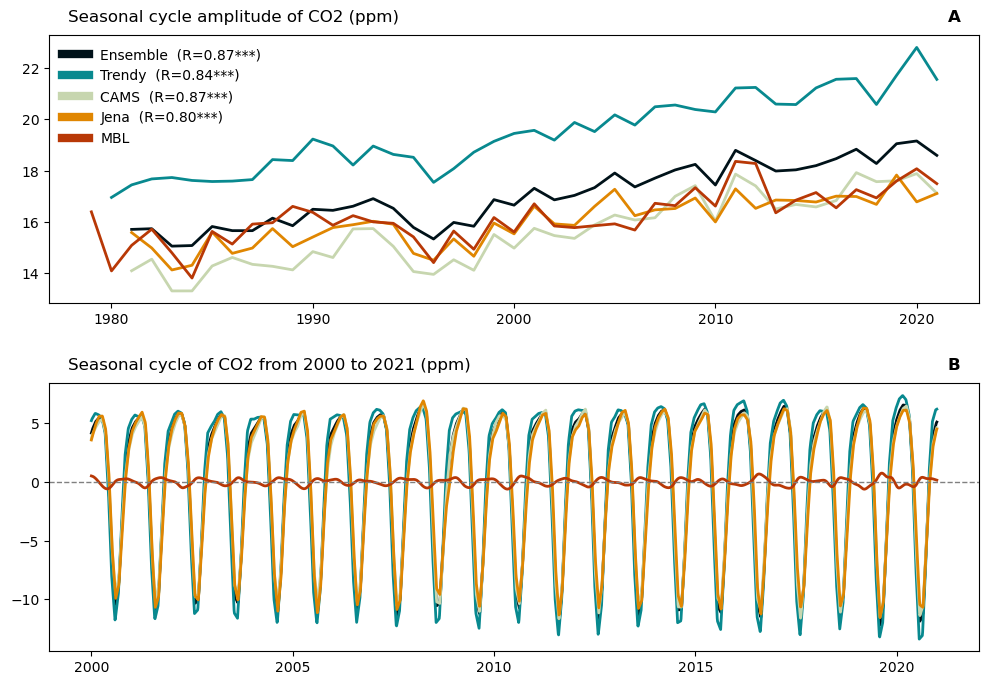

In [5]:
# 画图
fig = plt.figure(figsize=(12, 8))
axs = np.empty(2, dtype=object)
gs = gridspec.GridSpec(2, 1, height_ratios=[1, 1], hspace=0.3)
axs[0] = fig.add_subplot(gs[0])
axs[1] = fig.add_subplot(gs[1])

color_map = ['#001219', '#005f73', '#0a9396', '#94d2bd', '#e9d8a6',
             '#ee9b00', '#ca6702', '#bb3e03', '#ae2012', '#9b2226']
cm_custom = LinearSegmentedColormap.from_list('custom', color_map)
color_list = [cm_custom(i / 5) for i in range(5)]

ds = xr.open_dataset('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Fig-1-site+model/MBL.nc')
mbl_amp = ds['amp'].values
time_temp = ds['time'].values

corr, p = [], []
for n_m, (model, info) in enumerate(model_dict.items()):
    amp = info['amp'][0]
    time = info['time']
    corr.append(pearsonr(amp, mbl_amp[-len(amp):])[0])
    p.append(pearsonr(amp, mbl_amp[-len(amp):])[1])
    axs[0].plot(time, amp, label=model, color=color_list[n_m], linewidth=2)

    SC = info['SC_smooth'][0]
    time_smooth = info['time_smooth']
    idx = np.where((time_smooth >= 2000) & (time_smooth <= 2021))[0]
    axs[1].plot(time_smooth[idx], SC[idx], label=model, color=color_list[n_m], linewidth=2)

print("Correlation coefficients:", corr, "P-values:", p)

axs[0].plot(time_temp, mbl_amp, label='MBL', color=color_list[n_m+1], linewidth=2)
idx = np.where((time_mbl >= 2000) & (time_mbl <= 2021))[0]
axs[1].plot(time_mbl[idx], mbl_SC[idx], label='MBL', color=color_list[n_m+1], linewidth=2)
axs[0].yaxis.set_major_locator(MultipleLocator(2))
axs[1].axhline(0, color='gray', linestyle='--', linewidth=1)

letters = ['A', 'B']
titles = ['Seasonal cycle amplitude of CO2 (ppm)', 'Seasonal cycle of CO2 from 2000 to 2021 (ppm)']
for i in range(2):
    axs[i].text(0.02, 1.04, titles[i], transform=axs[i].transAxes, fontsize=12, va='bottom', ha='left')
    axs[i].text(0.98, 1.04, letters[i], transform=axs[i].transAxes, fontsize=12, va='bottom', ha='right', fontweight='bold')

custom_line = [plt.Line2D([0], [0], color=color_list[i], lw=6) for i in range(len(model_dict)+1)]
custom_label = [f"{model}  (R={corr[i]:.2f}***)" for i, model in enumerate(model_dict.keys())] + ['MBL']
axs[0].legend(custom_line, custom_label, loc='upper left', fontsize=10, frameon=False)

fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-3-GC-amp+SC.png', dpi=500,
            bbox_inches='tight', pad_inches=0.1)

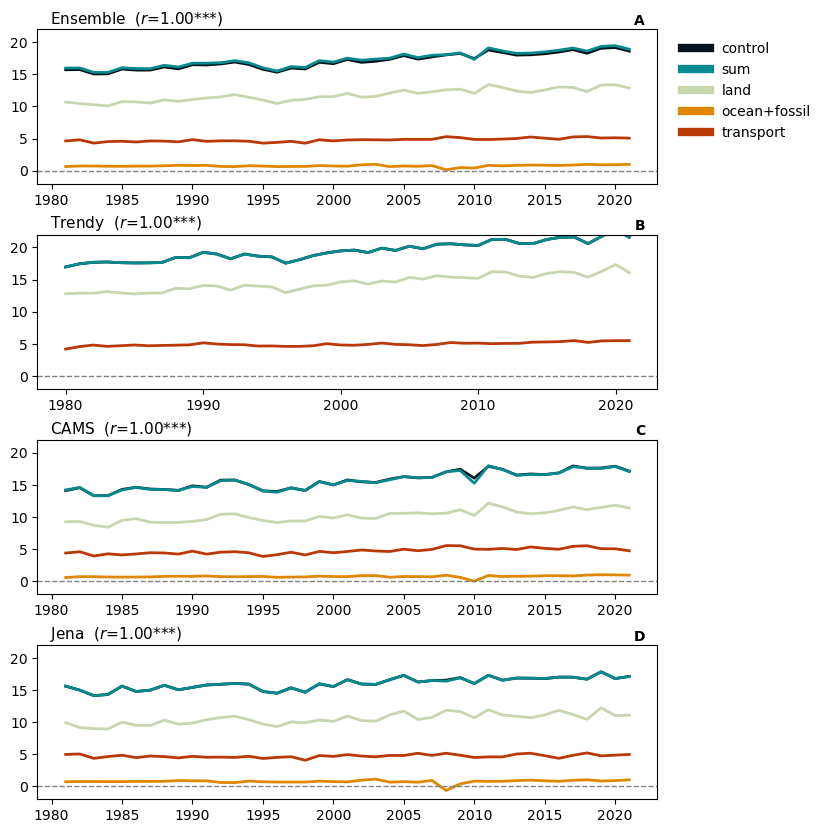

In [6]:
fig = plt.figure(figsize=(8, 10))
axs = np.empty(4, dtype=object)
gs = gridspec.GridSpec(4, 1, height_ratios=[1]*4, hspace=0.33)
for i in range(4):
    axs[i] = fig.add_subplot(gs[i])

exp_list = ['control', 'sum', 'land', 'ocean+fossil', 'transport']
color_map = ['#001219', '#005f73', '#0a9396', '#94d2bd', '#e9d8a6',
             '#ee9b00', '#ca6702', '#bb3e03', '#ae2012', '#9b2226']
cm_custom = LinearSegmentedColormap.from_list('custom', color_map)
color_list = [cm_custom(i / 5) for i in range(5)]

# 用一个空列表来动态存储包含计算结果的标题
titles = []

for n_m, (model, info) in enumerate(model_dict.items()):
    ax = axs[n_m]
    if model != 'Trendy':
        amp = info['amp']
        exp_list_model = info['exp_list']
        color_temp = color_list
    else:
        amp = info['amp'][[0, 1, -1]]
        exp_list_model = info['exp_list'][[0, 1, -1]]
        color_temp = [color_list[0], color_list[1], color_list[2], color_list[-1]]
        
    amp_sum = np.nansum(amp[1:], axis=0)
    amp = np.insert(amp, 1, amp_sum, axis=0)
    
    # 计算 sum (amp[1]) 与 control (amp[0]) 的 Pearson r 和 R2
    r_val, _ = pearsonr(amp[0], amp[1])
    r2_val = r_val ** 2
    titles.append(f"{model}  ($r$={r_val:.2f}***)")
    
    time = info['time']
    for n_e in range(amp.shape[0]):
        ax.plot(time, amp[n_e], linewidth=2, color=color_temp[n_e])
    
    ax.set_ylim(-2, 22)
    ax.axhline(0, color='gray', linestyle='--', linewidth=1)

letters = ['A', 'B', 'C', 'D']
for i in range(4):
    axs[i].text(0.02, 1.01, titles[i], transform=axs[i].transAxes, fontsize=11, va='bottom', ha='left')
    axs[i].text(0.98, 1.01, letters[i], transform=axs[i].transAxes, fontsize=10, va='bottom', ha='right', fontweight='bold')

custom_line = [plt.Line2D([0], [0], color=color_list[i], lw=6) for i in range(len(exp_list))]
custom_label = exp_list
axs[0].legend(custom_line, custom_label, loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=10, frameon=False)

fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-3-GC-amp-line.png', dpi=500,
            bbox_inches='tight', pad_inches=0.1)

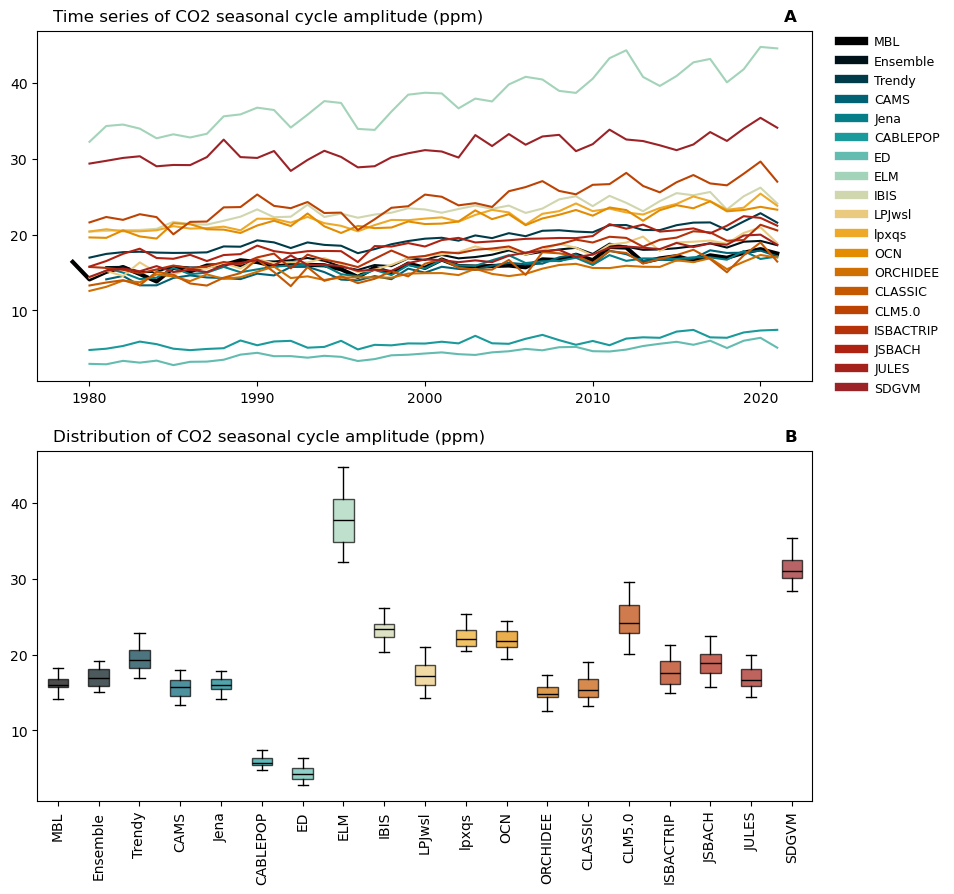

In [7]:
# Trendy
fig = plt.figure(figsize=(10, 10))
gs = gridspec.GridSpec(2, 1, height_ratios=[1, 1], hspace=0.2)
axs = np.empty(2, dtype=object)
for i in range(2):
    axs[i] = fig.add_subplot(gs[i])

# 1. 合并所有数据到一个统一的字典 plot_data
plot_data = {}

# 加入观测 MBL
plot_data['MBL'] = {'time': time_temp, 'amp': mbl_amp}

# 加入 model_dict
for model, info in model_dict.items():
    # 通常 model_dict 里的 amp 是多维的, index 0 对应 control
    amp = info['amp'][0] if info['amp'].ndim > 1 else info['amp']
    plot_data[model] = {'time': info['time'], 'amp': amp}

# 加入 Trendy_dict
for model, info in Trendy_dict.items():
    if model not in plot_data:  # 避免重复加入 'Trendy'
        amp = info['amp'][0] if info['amp'].ndim > 1 else info['amp']
        plot_data[model] = {'time': info['time'], 'amp': amp}

model_names = list(plot_data.keys())
n_m = len(model_names)

# 生成颜色：第一个（MBL）为黑色，其余使用 colormap 映射
color_map = ['#001219', '#005f73', '#0a9396', '#94d2bd', '#e9d8a6',
             '#ee9b00', '#ca6702', '#bb3e03', '#ae2012', '#9b2226']
cm_custom = LinearSegmentedColormap.from_list('custom', color_map)
color_list = ['black'] + [cm_custom(i / max(1, n_m - 2)) for i in range(n_m - 1)]

box_data = []

ax0 = axs[0]
for i, model in enumerate(model_names):
    time = plot_data[model]['time']
    amp = plot_data[model]['amp']
    
    lw = 3 if model == 'MBL' else 1.5
    ax0.plot(time, amp, label=model, color=color_list[i], linewidth=lw)
    box_data.append(amp)

# 在 axs[1] 绘制箱线图
ax1 = axs[1]
bplot = ax1.boxplot(box_data, patch_artist=True, showfliers=False, medianprops=dict(color='black'))

# 为箱线图填充对应的颜色
for patch, color in zip(bplot['boxes'], color_list):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# 设置 axs[1] 的 X 轴标签
ax1.set_xticklabels(model_names, rotation=90, ha='center', fontsize=10)

# 生成图例
custom_line = [plt.Line2D([0], [0], color=color_list[i], lw=6) for i in range(n_m)]
axs[0].legend(custom_line, model_names, loc='upper left', bbox_to_anchor=(1.02, 1.02), fontsize=9, frameon=False, ncol=1)
axs[0].text(0.02, 1.02, 'Time series of CO2 seasonal cycle amplitude (ppm)',
            transform=axs[0].transAxes, fontsize=12, va='bottom', ha='left')
axs[1].text(0.02, 1.02, 'Distribution of CO2 seasonal cycle amplitude (ppm)',
            transform=axs[1].transAxes, fontsize=12, va='bottom', ha='left')
letters = ['A', 'B']
for i in range(2):
    axs[i].text(0.98, 1.02, letters[i], transform=axs[i].transAxes, fontsize=12, 
                va='bottom', ha='right', fontweight='bold')

fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-3-GC-amp-disturbution.png', dpi=500,
            bbox_inches='tight', pad_inches=0.1)